Python: c:\Users\hp\anaconda3\python.exe
Pandas: 2.3.3
NumPy: 2.3.5
Matplotlib: 3.10.0
FastF1: 3.8.3
Scikit-learn: 1.8.0


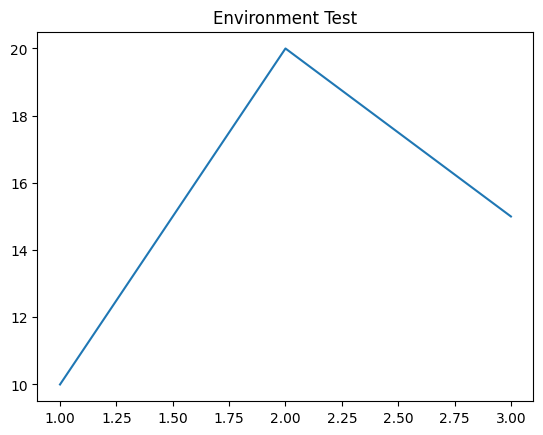

In [7]:
import sys
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import fastf1
import sklearn

print("Python:", sys.executable)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)
print("FastF1:", fastf1.__version__)
print("Scikit-learn:", sklearn.__version__)

plt.plot([1, 2, 3], [10, 20, 15])
plt.title("Environment Test")
plt.show()

In [8]:
from pathlib import Path
import fastf1

project_dir = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

data_dir = project_dir / "data"
cache_dir = data_dir / "fastf1_cache"

data_dir.mkdir(parents=True, exist_ok=True)
cache_dir.mkdir(parents=True, exist_ok=True)

fastf1.Cache.enable_cache(str(cache_dir))

print("Project directory:", project_dir)
print("Cache directory:", cache_dir)
print("FastF1 cache configured!")

Project directory: c:\Users\hp\Desktop\F1_Telemetory
Cache directory: c:\Users\hp\Desktop\F1_Telemetory\data\fastf1_cache
FastF1 cache configured!


In [9]:
session = fastf1.get_session(2024, "British Grand Prix", "Q")

session.load()

print("Session loaded successfully!")
print("Total laps:", len(session.laps))
print("Drivers:", session.laps["Driver"].unique())

core           INFO 	Loading data for British Grand Prix - Qualifying [v3.8.3]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info


req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
core        WARNING 	Fixed incorrect tyre stint information for driver '18'
req            INFO 	Using cached data for car_data
req            INFO 	Using cached data for position_data
req            INFO 	Using cached data for weather_data
req            INFO 	Using cached data for race_control_messages
core           INFO 	Finished loading data for 20 drivers: ['63', '44', '4', '1', '81', '27', '55', '18', '23', '14', '16', '2', '22', '24', '3', '77', '20', '31', '11', '10']


Session loaded successfully!
Total laps: 368
Drivers: ['RUS' 'HAM' 'NOR' 'VER' 'PIA' 'HUL' 'SAI' 'STR' 'ALB' 'ALO' 'LEC' 'SAR'
 'TSU' 'ZHO' 'RIC' 'BOT' 'MAG' 'OCO' 'PER' 'GAS']


In [10]:
laps = session.laps

display(laps.head())
print("Dataset shape:", laps.shape)
print("Available columns:")
print(laps.columns.tolist())

,Time,Driver,DriverNumber,LapTime,LapNumber,Stint,PitOutTime,PitInTime,Sector1Time,Sector2Time,...,FreshTyre,Team,LapStartTime,LapStartDate,TrackStatus,Position,Deleted,DeletedReason,FastF1Generated,IsAccurate
0,0 days 00:15:19.601000,RUS,63,NaT,1.0,1.0,0 days 00:13:30.333000,NaT,NaT,0 days 00:00:43.698000,...,True,Mercedes,0 days 00:13:30.333000,2024-07-06 14:00:43.342,1,NaN,False,,False,False
1,0 days 00:16:57.401000,RUS,63,0 days 00:01:37.800000,2.0,1.0,NaT,NaT,0 days 00:00:30.831000,0 days 00:00:39.784000,...,True,Mercedes,0 days 00:15:19.601000,2024-07-06 14:02:32.610,1,NaN,False,,False,True
2,0 days 00:19:04.796000,RUS,63,0 days 00:02:07.395000,3.0,1.0,NaT,NaT,0 days 00:00:42.237000,0 days 00:00:53.886000,...,True,Mercedes,0 days 00:16:57.401000,2024-07-06 14:04:10.410,1,NaN,False,,False,True
3,0 days 00:20:42.011000,RUS,63,0 days 00:01:37.215000,4.0,1.0,NaT,NaT,0 days 00:00:30.704000,0 days 00:00:39.456000,...,True,Mercedes,0 days 00:19:04.796000,2024-07-06 14:06:17.805,1,NaN,False,,False,True
4,0 days 00:22:29.979000,RUS,63,0 days 00:01:47.968000,5.0,1.0,NaT,0 days 00:22:24.033000,0 days 00:00:35.889000,0 days 00:00:44.201000,...,True,Mercedes,0 days 00:20:42.011000,2024-07-06 14:07:55.020,1,NaN,False,,False,False


Dataset shape: (368, 31)
Available columns:
['Time', 'Driver', 'DriverNumber', 'LapTime', 'LapNumber', 'Stint', 'PitOutTime', 'PitInTime', 'Sector1Time', 'Sector2Time', 'Sector3Time', 'Sector1SessionTime', 'Sector2SessionTime', 'Sector3SessionTime', 'SpeedI1', 'SpeedI2', 'SpeedFL', 'SpeedST', 'IsPersonalBest', 'Compound', 'TyreLife', 'FreshTyre', 'Team', 'LapStartTime', 'LapStartDate', 'TrackStatus', 'Position', 'Deleted', 'DeletedReason', 'FastF1Generated', 'IsAccurate']


In [11]:
drivers=session.laps["Driver"].unique()
print("Availble drivers:")
print(drivers)

Availble drivers:
['RUS' 'HAM' 'NOR' 'VER' 'PIA' 'HUL' 'SAI' 'STR' 'ALB' 'ALO' 'LEC' 'SAR'
 'TSU' 'ZHO' 'RIC' 'BOT' 'MAG' 'OCO' 'PER' 'GAS']


In [13]:
driver_1="VER"
driver_2="NOR"
lap_1=(session.laps.pick_drivers(driver_1).pick_fastest())
lap_2=(session.laps.pick_drivers(driver_2).pick_fastest())

print("Driver 1:",driver_1,"| Lap Time:",lap_1["LapTime"])
print("Driver 2:",driver_2,"| Lap Time:",lap_2["LapTime"])

Driver 1: VER | Lap Time: 0 days 00:01:26.203000
Driver 2: NOR | Lap Time: 0 days 00:01:26.030000


In [14]:
telemetry_1=lap_1.get_telemetry()
telemetry_2=lap_2.get_telemetry()

print("Driver 1 telemetry shape:",telemetry_1.shape)
print("Driber 2 telemetry shape:",telemetry_2.shape)

Driver 1 telemetry shape: (659, 18)
Driber 2 telemetry shape: (652, 18)


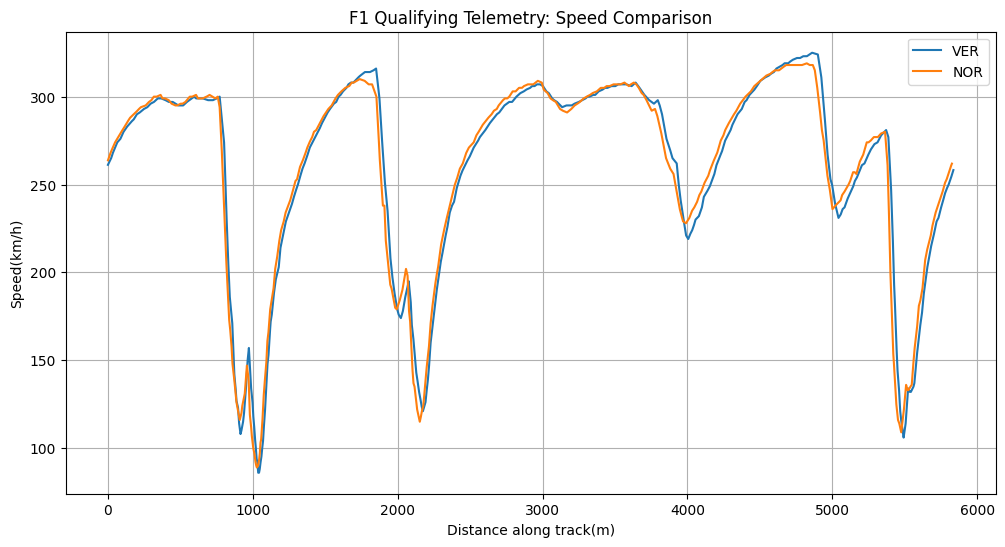

In [15]:
plt.figure(figsize=(12,6))
plt.plot(
    telemetry_1["Distance"],
    telemetry_1["Speed"],
    label=driver_1
)

plt.plot(
    telemetry_2["Distance"],
    telemetry_2["Speed"],
    label=driver_2
)
plt.xlabel("Distance along track(m)")
plt.ylabel("Speed(km/h)")
plt.title("F1 Qualifying Telemetry: Speed Comparison")
plt.legend()
plt.grid(True)
plt.show()

In [16]:
lap_time_1=lap_1["LapTime"].total_seconds()
lap_time_2=lap_2["LapTime"].total_seconds()
print(f"{driver_1} lap_time: {lap_time_1:.3f} seconds")
print(f"{driver_2} lap time: {lap_time_2:.3f} seconds")
difference=abs(lap_time_1-lap_time_2)
print(f"Lap-time difference:{difference:.3f}seconds")

VER lap_time: 86.203 seconds
NOR lap time: 86.030 seconds
Lap-time difference:0.173seconds


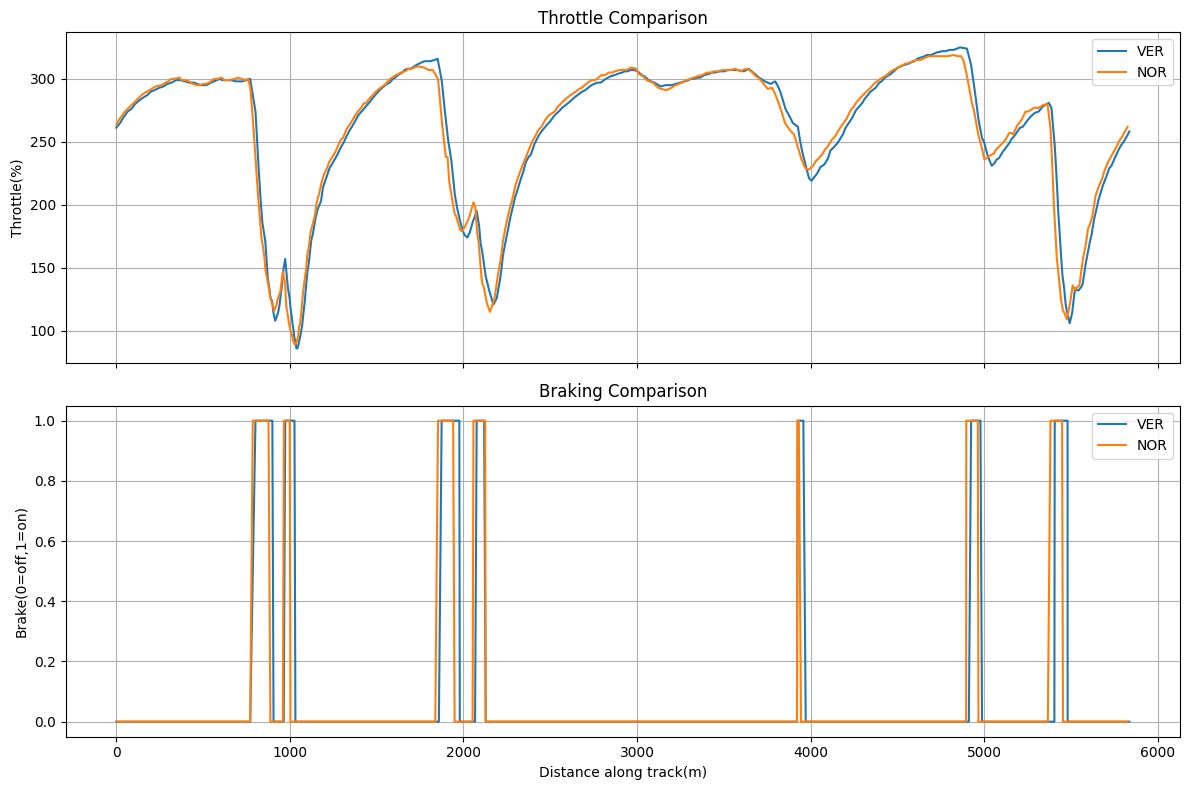

In [17]:
fig,axes=plt.subplots(2,1,figsize=(12,8),sharex=True)
axes[0].plot(
    telemetry_1["Distance"],
    telemetry_1["Speed"],
    label=driver_1
)
axes[0].plot(
    telemetry_2["Distance"],
    telemetry_2["Speed"],
    label=driver_2
)
axes[0].set_ylabel("Throttle(%)")
axes[0].set_title("Throttle Comparison")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    telemetry_1["Distance"],
    telemetry_1["Brake"].astype(int),
    label=driver_1
)
axes[1].plot(
    telemetry_2["Distance"],
    telemetry_2["Brake"].astype(int),
    label=driver_2
)
axes[1].set_xlabel("Distance along track(m)")
axes[1].set_ylabel("Brake(0=off,1=on)")
axes[1].set_title("Braking Comparison")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [19]:
from pathlib import Path
figures_dir=project_dir/"figures"
figures_dir.mkdir(parents=True,exit_ok=True)

plt.figure(figsize=(12,6))
plt.plot(telemetry_1["Distance"],telemetry_1["Speed"],label=driver_1)
plt.plot(telemetry_2["Distance"],telemetry_2["Speed"],label=driver_2)

plt.xlabel("Distance(m)")
plt.ylabel("Speed(km/h)")
plt.title("Qualifying Speed Comparison")
plt.legend()
plt.grid(True)

plt.savefig(
    figure_dir/"speed_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
print("Graph Saved!")

TypeError: Path.mkdir() got an unexpected keyword argument 'exit_ok'. Did you mean 'exist_ok'?